# Moon window: de Gerlache crater (LOLA 80 m south polar DEM)
Cuts a 40 km x 40 km square out of the LRO LOLA `LDEM_80S_80M` elevation map, centred on a crater, so it can be compared with the Earth window from `earth_dem.ipynb`. Every scale, offset, radius and pole position is **read from the label file**, not typed in.

## Step 1: Settings
**Config cell.** The only cell to edit to cut a different crater. The centre is taken from the IAU Gazetteer of Planetary Nomenclature (https://planetarynames.wr.usgs.gov/Feature/1439, first of three listed solutions: -88.48, -88.34, diameter 32.71 km). The Gazetteer gives other sets (-88.45, -90.45) and (-88.50, -87.10), so the centre is **provisional**. In our orientation test the deepest part of the floor sat a few km south-west of this point, so it may be on the inner wall.

In [2]:
from pathlib import Path

# ---- SITE SETTINGS: edit only this cell for another crater ----
SITE_NAME = "de Gerlache"
CENTRE_LAT = -88.48   # degrees; negative = south (Gazetteer, provisional)
CENTRE_LON = -88.34   # degrees east; negative = west (Gazetteer, provisional)
WINDOW_KM = 40        # side of the square window in kilometres (same as the Earth window)

root = Path.cwd().parent if Path.cwd().name == "pipeline" else Path.cwd()  # repo root; the notebook runs from /pipeline
IMG = root / "data" / "raw" / "LDEM_80S_80M.IMG"   # data/raw is read-only: we only ever read from it
LBL = root / "data" / "raw" / "LDEM_80S_80M.LBL"

## Step 2: Read the label
**Label values.** The `.LBL` file describes the `.IMG` file in plain text (`KEY = value`). This cell reads it into a dictionary and pulls out the numbers we need, so none of them come from memory.

In [3]:
label = {}
for line in open(LBL):
    if "=" in line and not line.strip().startswith("/*"):   # skip comment lines
        key, value = line.split("=", 1)
        label.setdefault(key.strip(), value.strip())         # keep the first time a key appears

def num(key):
    return float(label[key].split()[0])  # "80 <m/pix>" -> 80.0 (drop the unit text)

rows, cols = int(num("LINES")), int(num("LINE_SAMPLES"))
scale, offset = num("SCALING_FACTOR"), num("OFFSET")
pixel_m = num("MAP_SCALE")                            # metres per pixel
radius_m = num("A_AXIS_RADIUS") * 1000                # label gives km; the Moon is a sphere here (A = B = C)
pole_line, pole_sample = num("LINE_PROJECTION_OFFSET"), num("SAMPLE_PROJECTION_OFFSET")  # where the pole sits, in pixels
lat0, lon0 = num("CENTER_LATITUDE"), num("CENTER_LONGITUDE")

# Stop early if the label is not what this notebook assumes
assert label["SAMPLE_TYPE"] == "LSB_INTEGER" and num("SAMPLE_BITS") == 16, "expected little-endian 16-bit integers"
assert "POLAR STEREOGRAPHIC" in label["MAP_PROJECTION_TYPE"], "expected polar stereographic"

print(f"Grid {rows} x {cols}, {pixel_m:.0f} m per pixel; height = DN * {scale}; label OFFSET {offset:.0f} is the reference radius (NOT added to heights)")
print(f"Sphere radius {radius_m:,.0f} m; projection centre lat {lat0:.0f}, lon {lon0:.0f}; pole at line/sample {pole_line}, {pole_sample}")

Grid 7600 x 7600, 80 m per pixel; height = DN * 0.5; label OFFSET 1737400 is the reference radius (NOT added to heights)
Sphere radius 1,737,400 m; projection centre lat -90, lon 0; pole at line/sample 3799.5, 3799.5


## Step 3: Open the image and check it against the label
**Open without loading.** `numpy.memmap` reads straight from the file on demand, so the 115 MB file is not copied into memory and never changed (`mode="r"`). The checks compare the file with what the label promises: file size, and the minimum and maximum raw values.

In [4]:
import numpy as np

assert IMG.stat().st_size == rows * cols * 2, "file size does not match the label"   # 2 bytes per 16-bit sample
dn = np.memmap(IMG, dtype="<i2", mode="r", shape=(rows, cols))  # "<i2" = little-endian signed 16-bit; dn = raw "digital numbers"

print("File size OK:", f"{IMG.stat().st_size:,} bytes")
print(f"Raw min / max: {dn.min()} / {dn.max()}   (label DERIVED_MINIMUM / MAXIMUM: {label['DERIVED_MINIMUM']} / {label['DERIVED_MAXIMUM']})")
print(f"Height min / max: {dn.min() * scale:.1f} m / {dn.max() * scale:.1f} m  (DN x {scale}; relative to the {radius_m/1000:.1f} km reference sphere)")

File size OK: 115,520,000 bytes
Raw min / max: -14592 / 14052   (label DERIVED_MINIMUM / MAXIMUM: -14592 / 14052)
Height min / max: -7296.0 m / 7026.0 m  (DN x 0.5; relative to the 1737.4 km reference sphere)


## Step 4: Crop a 40 km square around the crater
**Projection and crop.** A polar stereographic projection turns latitude/longitude into x/y metres measured from the pole (`pyproj` does the maths; `lat_ts` = pole means the scale is true at the pole, as the label says). Dividing by the pixel size and adding the pole's pixel position gives the crater's row and column. Orientation (row 0 = top, longitude 0 pointing up, east to the right) was checked against Shoemaker, de Gerlache and Haworth: all three craters appeared at their Gazetteer positions, and flipping x or y made them disappear.

In [5]:
from pyproj import CRS, Transformer

moon_ll = CRS.from_proj4(f"+proj=longlat +R={radius_m} +no_defs")  # lat/lon on the lunar sphere
moon_xy = CRS.from_proj4(f"+proj=stere +lat_0={lat0} +lat_ts={lat0} +lon_0={lon0} +R={radius_m} +units=m +no_defs")  # polar stereographic, metres
to_xy = Transformer.from_crs(moon_ll, moon_xy, always_xy=True)  # always_xy: longitude first, then latitude
to_ll = Transformer.from_crs(moon_xy, moon_ll, always_xy=True)

x, y = to_xy.transform(CENTRE_LON, CENTRE_LAT)       # metres east and north of the pole
centre_row = pole_line - y / pixel_m                  # row 0 is the top (+y), so rows grow as y falls
centre_col = pole_sample + x / pixel_m                # columns grow with +x (east)

n = round(WINDOW_KM * 1000 / pixel_m)                 # pixels across the window: 40 km / 80 m = 500
r0, c0 = round(centre_row) - n // 2, round(centre_col) - n // 2   # top-left corner of the crop
assert r0 >= 0 and c0 >= 0 and r0 + n <= rows and c0 + n <= cols, "window runs off the map"
window = dn[r0:r0 + n, c0:c0 + n].astype("float32") * scale        # crop first, then convert only these pixels to metres

# Round-trip check: the middle of the crop should map back to the crater's lat/lon
mid_x, mid_y = (c0 + n / 2 - 0.5 - pole_sample) * pixel_m, (pole_line - (r0 + n / 2 - 0.5)) * pixel_m
mid_lon, mid_lat = to_ll.transform(mid_x, mid_y)
print(f"Crater at row {centre_row:.1f}, column {centre_col:.1f}; crop rows {r0}:{r0+n}, columns {c0}:{c0+n}")
print(f"Window: {n} x {n} pixels = {n * pixel_m / 1000:.1f} x {n * pixel_m / 1000:.1f} km; NaNs: {int(np.isnan(window).sum())}")
print(f"Crop centre maps back to lat {mid_lat:.3f}, lon {mid_lon:.3f} (requested {CENTRE_LAT}, {CENTRE_LON}); off by at most half a pixel")
print(f"Height min / max in window: {window.min():.1f} m / {window.max():.1f} m")

Crater at row 3782.8, column 3223.6; crop rows 3533:4033, columns 2974:3474
Window: 500 x 500 pixels = 40.0 x 40.0 km; NaNs: 0
Crop centre maps back to lat -88.480, lon -88.309 (requested -88.48, -88.34); off by at most half a pixel
Height min / max in window: -2353.0 m / 1814.0 m


**Plot.** Elevation with a colourbar. The axes are kilometres from the middle of the window. The red cross is the Gazetteer centre.

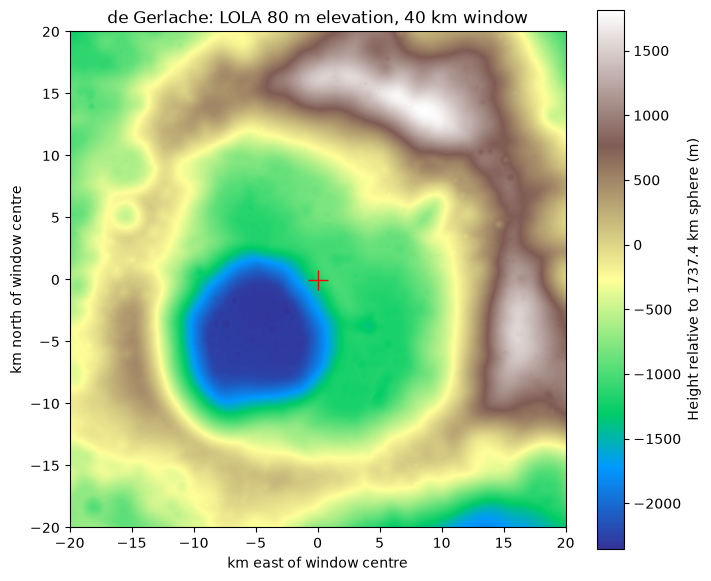

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
half = n * pixel_m / 2000                                  # half the window in km
im = ax.imshow(window, extent=[-half, half, -half, half], cmap="terrain")  # row 0 = top, as in the file
fig.colorbar(im, ax=ax, label="Height relative to 1737.4 km sphere (m)")
ax.plot((centre_col - c0 - n / 2 + 0.5) * pixel_m / 1000, -(centre_row - r0 - n / 2 + 0.5) * pixel_m / 1000, "r+", ms=14)  # Gazetteer centre
ax.set_title(f"{SITE_NAME}: LOLA 80 m elevation, {WINDOW_KM} km window")
ax.set_xlabel("km east of window centre")
ax.set_ylabel("km north of window centre")
plt.show()